In [11]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


In [12]:
# df = pd.read_csv('../results/active-testing/dr-budget-curves-20261029-112547-406234-47d24f02b77c4ee6882dd24f0207f671.csv')
df = pd.read_csv('../results/active-testing/dr-budget-curves-20261102-120602-420363-bd9f0d0b933446e38adfee6d1b065260.csv')
df.head()

,n_labels,risk,method,risk female,risk male,n_labels_female,n_labels_male,repetition,seed,full_pool_risk,full_pool_size
0,10,0.199650,UniformSampleMean,0.161204,0.257318,6,4,1,735139175,0.285665,1000
1,20,0.216121,UniformSampleMean,0.189716,0.255729,12,8,1,735139175,0.285665,1000
2,30,0.209267,UniformSampleMean,0.215865,0.197871,19,11,1,735139175,0.285665,1000
3,40,0.247225,UniformSampleMean,0.282052,0.182547,26,14,1,735139175,0.285665,1000
4,50,0.296608,UniformSampleMean,0.352445,0.188217,33,17,1,735139175,0.285665,1000


<Axes: xlabel='n_labels', ylabel='risk'>

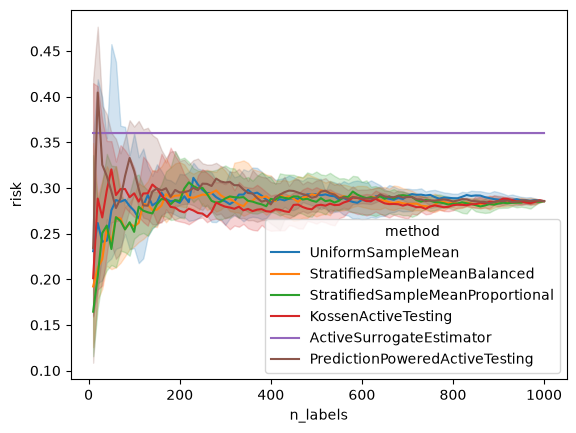

In [13]:
sns.lineplot(data=df, x='n_labels', y='risk', hue='method', estimator="median")

In [14]:
df['risk_error'] = (df['risk'] - df['full_pool_risk']).abs()

<Axes: xlabel='n_labels', ylabel='risk_error'>

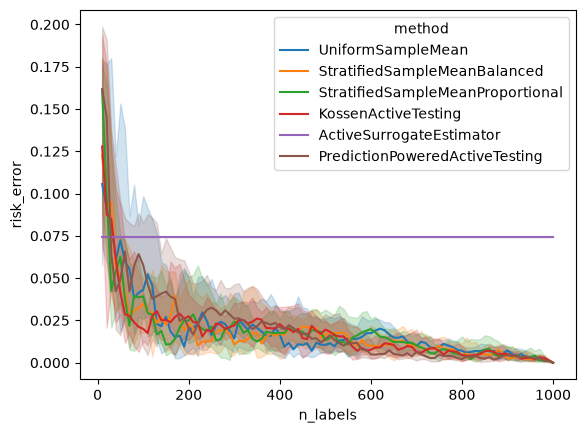

In [15]:
sns.lineplot(data=df, x='n_labels', y='risk_error', hue='method', estimator="median")

In [ ]:
# Bootstrap the budget curves grouped by repitition, since they are dependent 
# within each repetition. This is done by sampling the repetitions with 
# replacement, and then calculating the median risk for each method at each 
# budget level.

rng = np.random.default_rng(42)
B = 5000
results = []

for method, g in df.groupby("method"):
    # Rows = repetitions, columns = budgets
    wide = g.pivot(index="repetition", columns="n_labels", values="risk_error")
    x = wide.to_numpy()
    n = len(x)

    # Resample repetitions (same indices across all budgets)
    idx = rng.integers(n, size=(B, n))
    boot = np.median(x[idx], axis=1)  # (B, n_budgets)

    results.append(pd.DataFrame({
        "method": method,
        "budget": wide.columns,
        "median": np.median(x, axis=0),
        "lower": np.quantile(boot, 0.025, axis=0),
        "upper": np.quantile(boot, 0.975, axis=0),
    }))

result = pd.concat(results, ignore_index=True)

In [17]:
result.head()

,method,budget,median,lower,upper
0,ActiveSurrogateEstimator,10,0.35972,0.35972,0.35972
1,ActiveSurrogateEstimator,20,0.35972,0.35972,0.35972
2,ActiveSurrogateEstimator,30,0.35972,0.35972,0.35972
3,ActiveSurrogateEstimator,40,0.35972,0.35972,0.35972
4,ActiveSurrogateEstimator,50,0.35972,0.35972,0.35972


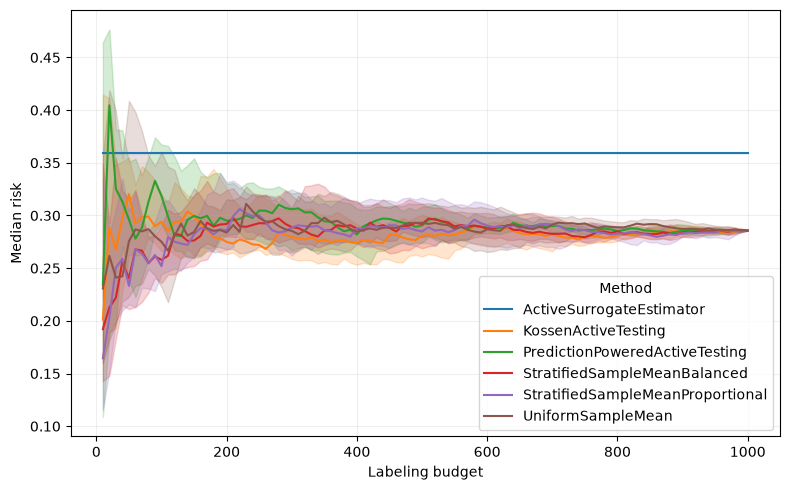

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))

for method, g in result.groupby("method"):
    g = g.sort_values("budget")

    line, = ax.plot(g["budget"], g["median"], label=method)
    ax.fill_between(
        g["budget"], g["lower"], g["upper"],
        color=line.get_color(), alpha=0.2
    )

ax.set(xlabel="Labeling budget", ylabel="Median risk")
ax.legend(title="Method")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()